# Fixed-point amplitude amplification

This original implementation follows Yoder, Low and Chuang, *Fixed-Point Quantum Search with an Optimal Number of Queries*, PRL 113, 210501 (2014), DOI [10.1103/PhysRevLett.113.210501](https://doi.org/10.1103/PhysRevLett.113.210501), [arXiv:1409.3305](https://arxiv.org/abs/1409.3305).

A supplied coherent preparation A and good-register predicate are required. The schedule uses a lower bound w, without reading the exact initial success probability. The guarantee is ideal failure probability at most δ² for p≥w. Floating phases, numerical checks and conditional surface-code projections are distinct evidence.

The threshold preparation below has a trivial classical answer. It demonstrates explicit preparation, inverse and phased reflections; it is not an application speedup.

In [1]:
from pathlib import Path
import sys, os, math, json
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector, Operator
from IPython.display import display
root=Path.cwd()
if not (root/"src").exists() and (root.parent/"src").exists():
    root=root.parent
if (root/"src").exists():
    sys.path.insert(0,str(root/"src"))
try:
    from openquantum.amplitude_estimation import threshold_preparation
    from openquantum.fixed_point_amplification import (
        fixed_point_schedule, build_fixed_point_amplification,
        ideal_success_probability, good_probability, lower_fixed_point,
    )
except ModuleNotFoundError as error:
    if error.name not in {"openquantum", "openquantum.amplitude_estimation", "openquantum.fixed_point_amplification"}:
        raise
    # Standalone notebook: save the two source snapshots beside this file.
    from amplitude_estimation import threshold_preparation
    from fixed_point_amplification import (
        fixed_point_schedule, build_fixed_point_amplification,
        ideal_success_probability, good_probability, lower_fixed_point,
    )
n_data, threshold, lower, delta = 2, 1, .1, .05
A=threshold_preparation(n_data,threshold)
schedule=fixed_point_schedule(lower,delta)
circuit=build_fixed_point_amplification(A,[n_data],1,lower,delta)
measured=circuit.copy()
measured.measure_all()
compiled=lower_fixed_point(measured)
print({"L":schedule.length,"rounds":schedule.rounds,
       "initial_success":threshold/2**n_data,"promise_w":lower,
       "ideal_failure_bound":schedule.ideal_failure_bound,
       "forward_A":circuit.metadata["preparation_calls"],
       "inverse_A":circuit.metadata["inverse_preparation_calls"]})

{'L': 13, 'rounds': 6, 'initial_success': 0.25, 'promise_w': 0.1, 'ideal_failure_bound': 0.0025000000000000005, 'forward_A': 7, 'inverse_A': 6}


## Explicit preparation and complete circuit

A applies Hadamards to the data and computes the reversible threshold flag. Each round applies good phase β, A†, all-zero phase −α, A and global π. The zero projector covers the complete data-plus-flag register. No dense unitary or initialized state replaces preparation or inversion.

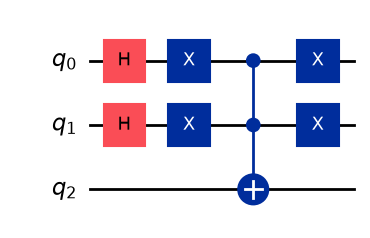

In [2]:
display(A.draw(output="mpl",style="iqp"))
plt.close("all")

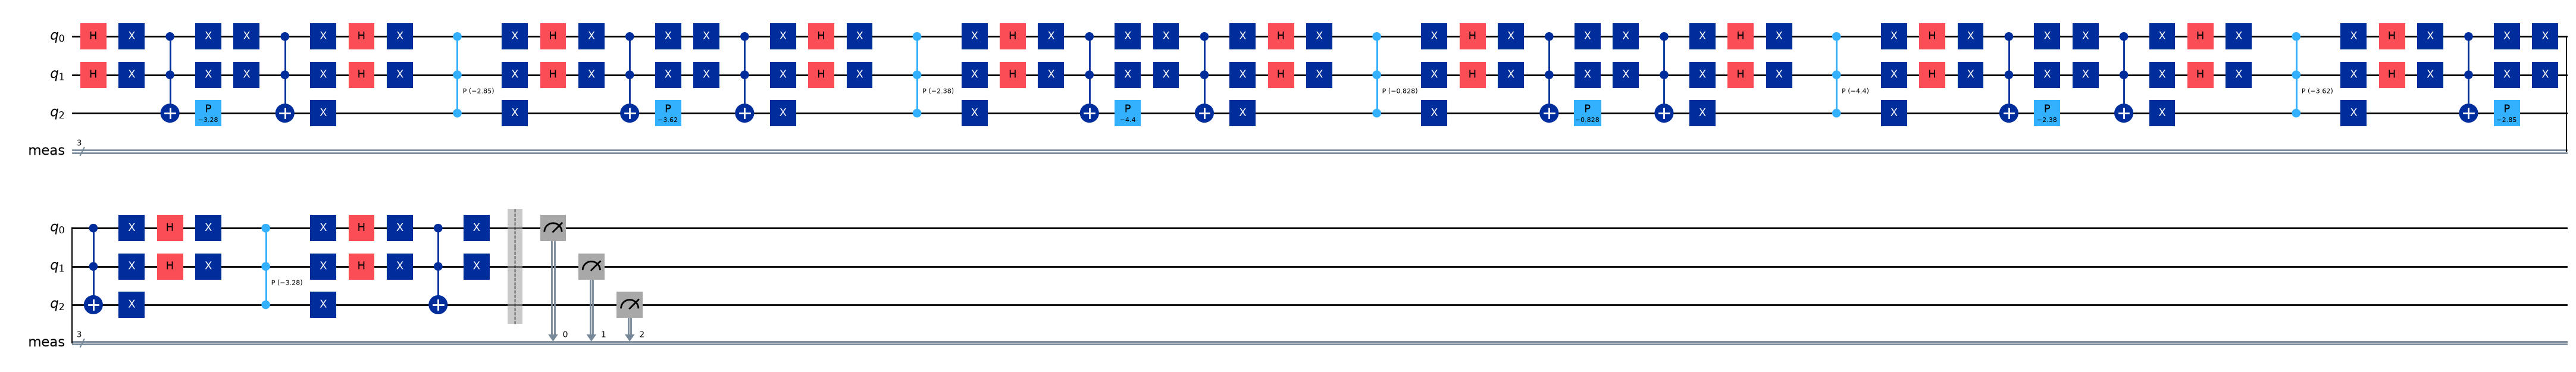

In [3]:
display(measured.draw(output="mpl",fold=65,style="iqp"))
plt.close("all")

## Independent probability and operator checks

The success law is 1−δ² T_L(√(1−p)/γ)², with γ=sech(acosh(1/δ)/L). A long-double polynomial recurrence independently checks the production trigonometric formula. Direct source/target projector matrices independently check the full operator, including global phase.

In [4]:
def recurrence_success(p,L,delta):
    if p in (0.,1.):return p
    gamma=np.longdouble(1)/np.cosh(np.arccosh(np.longdouble(1)/delta)/L)
    x=np.sqrt(np.longdouble(1)-p)/gamma
    previous,current=np.longdouble(1),x
    for _ in range(2,L+1):previous,current=current,2*x*current-previous
    return float(1-(np.longdouble(delta)*current)**2)
p=threshold/2**n_data
actual=good_probability(circuit,[n_data],1)
expected=recurrence_success(p,schedule.length,delta)
assert abs(actual-expected)<2e-12
assert abs(ideal_success_probability(p,schedule)-expected)<2e-12
a=Operator(A).data
psi=a[:,0]
identity=np.eye(len(psi),dtype=complex)
good=np.diag([int((i>>n_data)&1) for i in range(len(psi))])
reference=a.copy()
for alpha,beta in zip(schedule.alphas,schedule.betas,strict=True):
    reference=-(identity+(np.exp(-1j*alpha)-1)*np.outer(psi,psi.conj())) @ (identity+(np.exp(1j*beta)-1)*good) @ reference
operator_error=float(np.max(np.abs(Operator(circuit).data-reference)))
state_error=float(np.max(np.abs(Statevector.from_instruction(circuit).data-
                               Statevector.from_instruction(compiled.remove_final_measurements(inplace=False)).data)))
assert operator_error<2e-12 and state_error<2e-12
print({"simulated_success":actual,"recurrence_success":expected,
       "full_operator_max_error":operator_error,"lowered_state_max_error":state_error})

{'simulated_success': 0.9979791728712184, 'recurrence_success': 0.9979791728712227, 'full_operator_max_error': 1.9057088172464887e-15, 'lowered_state_max_error': 7.310841799453369e-15}


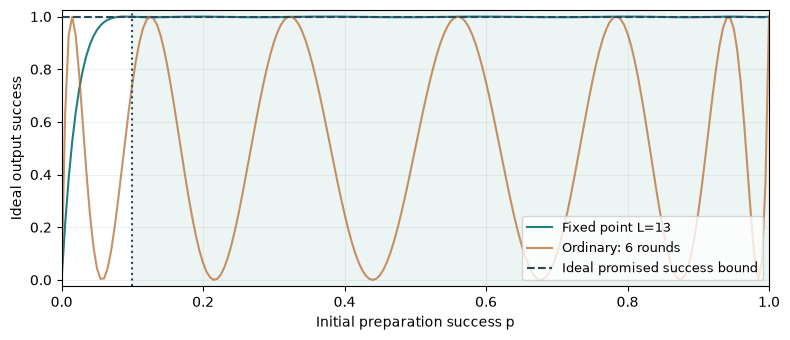

In [5]:
ps=np.linspace(0,1,201)
fig,ax=plt.subplots(figsize=(8,3.5))
ax.plot(ps,[recurrence_success(float(p),schedule.length,delta) for p in ps],label=f"Fixed point L={schedule.length}",color="#1f807e")
ax.plot(ps,np.sin(schedule.length*np.arcsin(np.sqrt(ps)))**2,label=f"Ordinary: {schedule.rounds} rounds",color="#b56325",alpha=.7)
ax.axvspan(lower,1,color="#1f807e",alpha=.08)
ax.axhline(1-delta**2,ls="--",color="#29485b",label="Ideal promised success bound")
ax.axvline(lower,ls=":",color="#29485b")
ax.set(xlabel="Initial preparation success p",ylabel="Ideal output success",ylim=(-.025,1.025),xlim=(0,1))
ax.legend(loc="lower right",fontsize=9)
ax.grid(alpha=.2)
plt.tight_layout()
display(fig)
plt.close(fig)

The shaded band begins at the promised lower bound. Below the promise, the uniform guarantee is unavailable. Fixed point means that a larger recomputed schedule expands the guaranteed band; success need not increase pointwise with L, and schedules are not prefixes.

In [6]:
# Several bounded actual circuits check endpoints and inputs below the promise.
from qiskit import QuantumCircuit
checked=0
maximum_error=0.
for p in [0.,.01,.05,.1,.25,.5,.9,1.]:
    preparation=QuantumCircuit(1)
    preparation.ry(2*math.asin(math.sqrt(p)),0)
    result=build_fixed_point_amplification(preparation,[0],1,lower,delta)
    err=abs(good_probability(result,[0],1)-recurrence_success(p,schedule.length,delta))
    maximum_error=max(maximum_error,err)
    assert err<2e-12
    checked+=1
print({"actual_circuits_checked":checked,"maximum_probability_error":maximum_error})

{'actual_circuits_checked': 8, 'maximum_probability_error': 1.2212453270876722e-15}


## Resource boundary and scaling

One measured trial pays initial preparation, every inverse/forward pair, every good/zero phase and all output measurements. Primitive lowering uses exact floating-angle rotations; a Clifford+T synthesis certificate is not produced. The separate generator computes the optional surface-code projections under two frozen illustrative profiles.

Logical zero inputs are assumed. Physical initialization/reset, external loading, classical verification/controller/decoder latency and concrete synthesis runtime tails are excluded. The default conditional allowance is δ² + 10⁻⁵ + 0.005 = 0.00751, only if the synthesis scalar bounds output-distribution variation and the physical model holds. It is not certified hardware confidence.

In [7]:
counts=dict(compiled.count_ops())
print({"live_qubits":compiled.num_qubits,
       "primitive_operations_including_readout":sum(v for k,v in counts.items() if k!="barrier"),
       "dependency_depth":compiled.depth(),"gate_counts":counts,
       "executions":1,"physical_initialization_cost_included":False})
# Size variation keeps p=1/4, w and δ fixed. It generates actual circuits;
# this cell deliberately does not simulate the larger generated circuits.
rows=[]
for n in [2,3,4,6,8]:
    source=build_fixed_point_amplification(threshold_preparation(n,2**(n-2)),[n],1,lower,delta,measure=True)
    lowered=lower_fixed_point(source)
    rows.append({"n_data":n,"live_qubits":lowered.num_qubits,
                 "operations_including_readout":sum(v for k,v in lowered.count_ops().items() if k!="barrier"),
                 "dependency_depth":lowered.depth(),"simulated_in_this_cell":False})
display(rows)

{'live_qubits': 3, 'primitive_operations_including_readout': 396, 'dependency_depth': 248, 'gate_counts': {'cx': 114, 'x': 88, 'h': 52, 't': 52, 'rz': 48, 'tdg': 39, 'measure': 3, 'barrier': 1}, 'executions': 1, 'physical_initialization_cost_included': False}


[{'n_data': 2,
  'live_qubits': 3,
  'operations_including_readout': 396,
  'dependency_depth': 248,
  'simulated_in_this_cell': False},
 {'n_data': 3,
  'live_qubits': 4,
  'operations_including_readout': 638,
  'dependency_depth': 380,
  'simulated_in_this_cell': False},
 {'n_data': 4,
  'live_qubits': 5,
  'operations_including_readout': 1048,
  'dependency_depth': 614,
  'simulated_in_this_cell': False},
 {'n_data': 6,
  'live_qubits': 7,
  'operations_including_readout': 2552,
  'dependency_depth': 1148,
  'simulated_in_this_cell': False},
 {'n_data': 8,
  'live_qubits': 9,
  'operations_including_readout': 4452,
  'dependency_depth': 1580,
  'simulated_in_this_cell': False}]

## Optional local or Binder controls

These controls regenerate an actual bounded three-wire circuit and verify its probability. Static publication keeps saved outputs and does not require a public Python backend. The controls run only in a live kernel. Save this notebook with both source snapshots, or use the public source package.

In [8]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    def explore(threshold=1, failure_amplitude=.05):
        source=build_fixed_point_amplification(threshold_preparation(2,threshold),[2],1,.1,failure_amplitude,measure=True)
        coherent=source.remove_final_measurements(inplace=False)
        chosen=fixed_point_schedule(.1,failure_amplitude)
        actual=good_probability(coherent,[2],1)
        reference=recurrence_success(threshold/4,chosen.length,failure_amplitude)
        assert abs(actual-reference)<2e-12
        print({"initial_p":threshold/4,"L":chosen.length,"ideal_output_success":actual,
               "ideal_failure_bound":chosen.ideal_failure_bound})
        display(source.draw(output="mpl",fold=65,style="iqp"))
        plt.close("all")
    widgets.interact(explore,threshold=widgets.IntSlider(value=1,min=1,max=3),
                     failure_amplitude=widgets.Dropdown(options=[.05,.1,.2,.5],value=.05))
else:
    print("Saved bounded outputs; launch a live kernel for controls.")

Saved bounded outputs; launch a live kernel for controls.


## Reproduce

From the source package, using its Python 3.12 lock:

```bash
python scripts/generate_fixed_point_amplification.py --estimate
python -m pytest tests/test_fixed_point_amplification.py
```

Qiskit core supplies gates, ideal statevectors and OpenQASM export. NumPy and Matplotlib supply numerical reference arithmetic and original plots. No Lean proof, verified compiler or hardware confidence certificate is integrated.